In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn scipy

Cell 2 – Import required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

Cell 3 – Load the dataset

In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")

print("First 5 records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

First 5 records:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abb

Cell 4 – Data preprocessing

In [4]:
# Select numerical features
data = df[
    ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
].copy()

# Remove missing values
data.dropna(inplace=True)

print("Selected Features:")
print(data.head())

print("\nDataset Shape:", data.shape)

Selected Features:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95

Dataset Shape: (2823, 4)


Cell 5 – Normalize the data
We use StandardScaler to bring all numerical features to a similar scale.

In [5]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)

print("Data Normalization Completed!")

print("\nScaled Data:")
print(scaled_data[:5])

Data Normalization Completed!

Scaled Data:
[[-0.52289086  0.5969775  -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372  0.17944282 -0.14224584]
 [ 1.01719493 -0.01975856  0.10470098 -0.14224584]
 [ 1.42788447  0.81015797  0.89673966 -0.14224584]]


Cell 6 – Determine optimal clusters using Elbow Method
The Elbow Method helps determine the optimal number of clusters by calculating WCSS (Within-Cluster Sum of Squares).

In [6]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    wcss.append(kmeans.inertia_)

print("WCSS Values:")
print(wcss)

WCSS Values:
[11292.000000000036, 6741.6905748085355, 4766.014280081654, 3934.894121194948, 3348.2685270796546, 2858.818306188108, 2548.5359725153385, 2350.6600480147927, 2169.967218236508, 2019.7529981769624]


Cell 7 – Plot Elbow Method graph

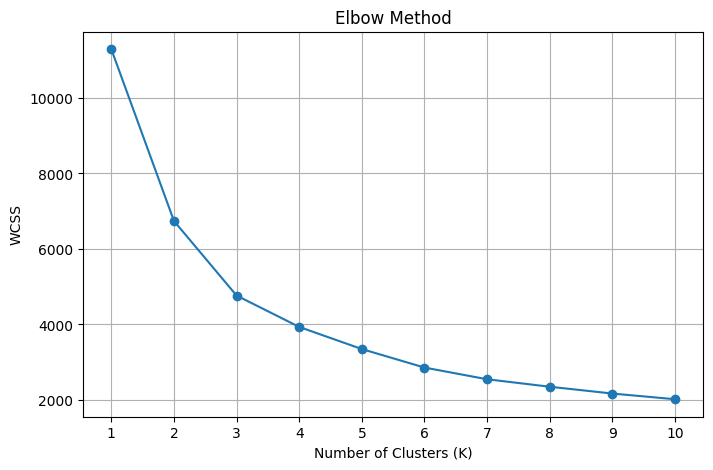

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.xticks(range(1, 11))
plt.grid()

plt.show()

Cell 8 – Implement K-Means Clustering

In [8]:
# Initialize K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model
kmeans.fit(scaled_data)

# Assign cluster labels
data["KMeans_Cluster"] = kmeans.labels_

print("K-Means Clustering Completed!")

print("\nCluster Labels:")
print(data["KMeans_Cluster"].head(10))

print("\nCluster Distribution:")
print(data["KMeans_Cluster"].value_counts())

K-Means Clustering Completed!

Cluster Labels:
0    2
1    2
2    1
3    1
4    1
5    2
6    2
7    1
8    2
9    1
Name: KMeans_Cluster, dtype: int32

Cluster Distribution:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


Cell 9 – Visualize K-Means clusters

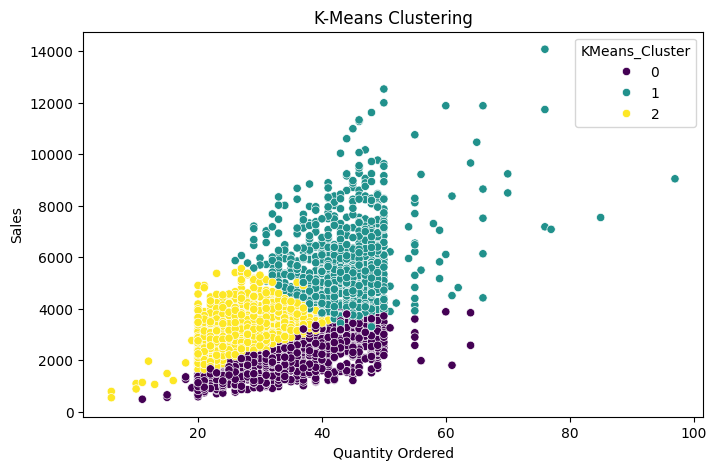

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=data["QUANTITYORDERED"],
    y=data["SALES"],
    hue=data["KMeans_Cluster"],
    palette="viridis"
)

plt.title("K-Means Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")

plt.show()

Cell 10 – Generate Dendrogram for Hierarchical Clustering

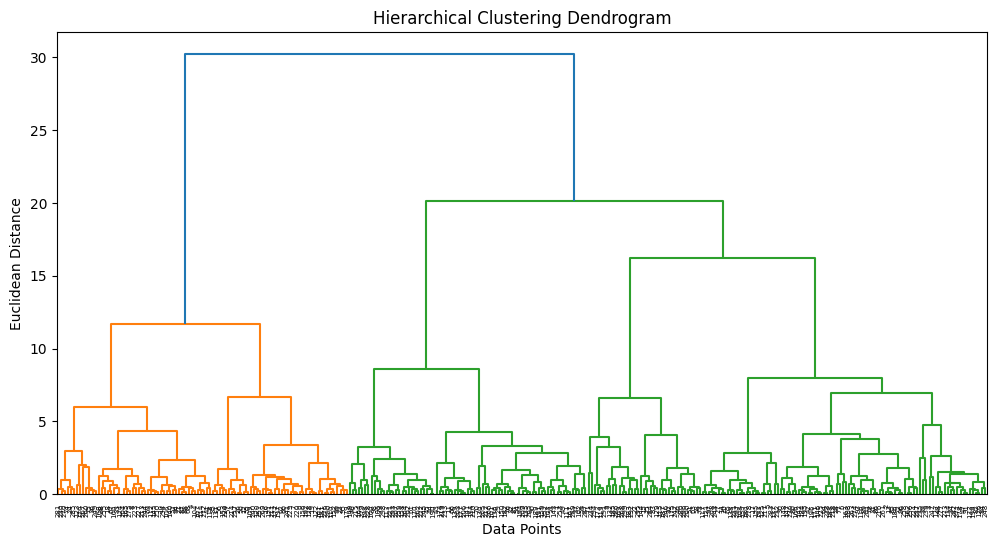

In [10]:
# Select sample data
sample_data = data.drop(
    columns=["KMeans_Cluster"]
).sample(
    n=min(300, len(data)),
    random_state=42
)

# Generate linkage matrix
linked = linkage(
    StandardScaler().fit_transform(sample_data),
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

Cell 11 – Implement Hierarchical Clustering

In [11]:
# Initialize hierarchical clustering
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Fit model and predict clusters
hc_labels = hc.fit_predict(scaled_data)

# Store cluster labels
data["Hierarchical_Cluster"] = hc_labels

print("Hierarchical Clustering Completed!")

print("\nCluster Labels:")
print(data["Hierarchical_Cluster"].head(10))

print("\nCluster Distribution:")
print(data["Hierarchical_Cluster"].value_counts())

Hierarchical Clustering Completed!

Cluster Labels:
0    2
1    2
2    0
3    0
4    1
5    0
6    2
7    1
8    2
9    1
Name: Hierarchical_Cluster, dtype: int64

Cluster Distribution:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


Cell 12 – Visualize Hierarchical Clusters

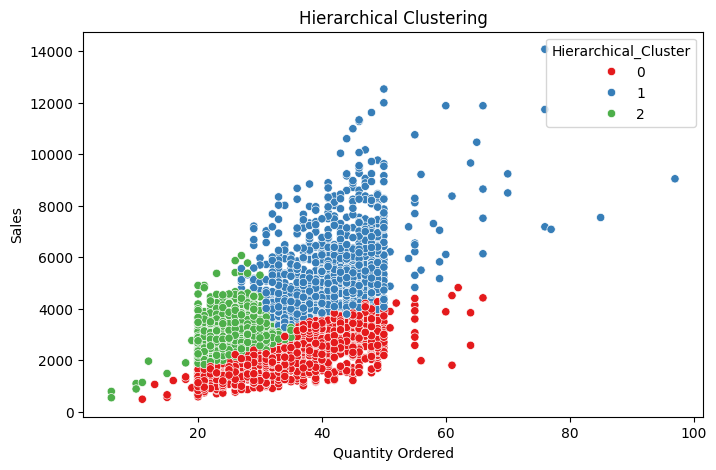

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=data["QUANTITYORDERED"],
    y=data["SALES"],
    hue=data["Hierarchical_Cluster"],
    palette="Set1"
)

plt.title("Hierarchical Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")

plt.show()